# Detecting Cyberbullying in Comments of posts on Facebook
***

The Beginning of the code:

In [2]:
import numpy as np #dealing with arrays
import pandas as pd #dealin with dataframes
import matplotlib.pyplot as plt #to visulaize the diagram
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, make_scorer
from time import time

from sklearn.naive_bayes import MultinomialNB # to build naive bayes model
from sklearn.tree import DecisionTreeClassifier # to build decision tree model
from sklearn.svm import LinearSVC # to build linearSVC Model
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
##from sklearn.externals import joblib


In [4]:
from google.colab import drive
drive.mount('/content/drive')

KeyboardInterrupt: 

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving cyberbullying 1.xlsx to cyberbullying 1.xlsx


### Loading and Analyzing the data
***

In [ ]:
import io
df=pd.read_excel(io.BytesIO(uploaded['cyberbullying 1.xlsx']))
df.head(30)


,comment,bullying
0,هههههههههه احلى شي,0
1,يا الله شو جلق وبايخ,1
2,الله يصطفل فيكي🙄🙄,2
3,ههههه #غباء,0
4,هيك شي 🙂www.eltsonlin.com,0
5,هههههههه,0
6,ليش عنجد الخبر@ali ali,0
7,تفاهة,3
8,قريبا حبيبي ادفعلي بدل,0
9,جلاقة,3


In [ ]:
df.shape

(3047, 2)

0     1895
3      594
1      302
2      105
5       69
6       31
7       19
10       9
11       8
4        6
8        5
9        4
Name: bullying, dtype: int64


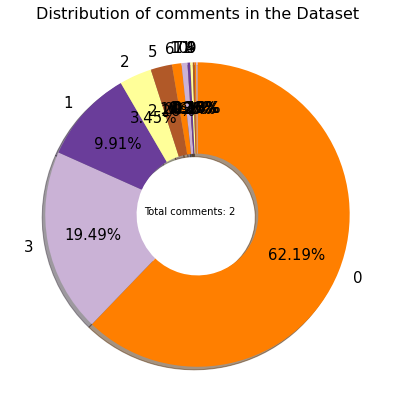

In [ ]:
plt.figure(figsize = (7,7))
sorted_counts = df['bullying'].value_counts()
print(sorted_counts)
plt.pie(sorted_counts, labels = sorted_counts.index, startangle = 90, counterclock = False, wedgeprops = {'width' : 0.6},
       autopct='%.2f%%', pctdistance = 0.7, textprops = {'color': 'black', 'fontsize' : 15}, shadow = True,
        colors = sns.color_palette("Paired")[7:])
plt.text(x = -0.35, y = 0, s = 'Total comments: {}'.format(df.shape[1]))
plt.title('Distribution of comments in the Dataset', fontsize = 16);

In [ ]:
df['bullying'] = df.bullying.map({'yes': 1, 'no': 0})

In [ ]:
df['bullying'] = df['bullying'].fillna(0).astype(np.int64)

In [ ]:
df.head()

,comment,bullying
0,هههههههههه احلى شي,0
1,يا الله شو جلق وبايخ,1
2,الله يصطفل فيكي🙄🙄,2
3,ههههه #غباء,0
4,هيك شي 🙂www.eltsonlin.com,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1801 entries, 0 to 1800
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   comment   1801 non-null   object
 1   bullying  1801 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 28.3+ KB


In [ ]:
df.columns

Index(['comment', 'bullying'], dtype='object')

Removing the arabic diacritics:

In [ ]:
import re
import string
import sys
import argparse
arabic_punctuations = '''`÷×؛<>_()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ'''
english_punctuations = string.punctuation
punctuations_list = arabic_punctuations + english_punctuations
print(punctuations_list)

`÷×؛<>_()*&^%][ـ،/:"؟.,'{}~¦+|!”…“–ـ!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [ ]:
arabic_diacritics = re.compile("""
                             ّ    | # Tashdid
                             َ    | # Fatha
                             ً    | # Tanwin Fath
                             ُ    | # Damma
                             ٌ    | # Tanwin Damm
                             ِ    | # Kasra
                             ٍ    | # Tanwin Kasr
                             ْ    | # Sukun
                             ـ     # Tatwil/Kashida
                         """, re.VERBOSE)
print(arabic_diacritics)

re.compile('\n                             ّ    | # Tashdid\n                             َ    | # Fatha\n                             ً    | # Tanwin Fath\n                             ُ    | # Damma\n         , re.VERBOSE)


In [ ]:
def remove_diacritics(text):
    text = re.sub(arabic_diacritics, '', text)
    return text

In [ ]:
df['comment']=df['comment'].apply(remove_diacritics)
df['comment'][1793]

'انت واحد سمج سميك زنخ كمخة '

Removin the URL:

In [ ]:
import re
df['comment'] = df['comment'].str.replace('http\S+|www.\S+', '', case=False)
df['comment'][1702]

'بحب شخصيتك وبموت فيها'

Removing digits:

In [ ]:

from string import digits
def clean_digits(text):
 clean_text=''.join(filter(lambda x: not x.isdigit(),text))
 return clean_text

In [ ]:
df['comment']=df['comment'].apply(clean_digits)
df['comment'][188]

'شو بردا وحدو الله ما صدقنا وصار الجو دافي شوي'

Removing mensions:

In [ ]:
import re
def clean_mensions(text):
 mentions = re.findall("@([a-zA-Z0-9_]{1,50})", text)
 clean_text = re.sub("@[A-Za-z0-9_]+","", text)
 return clean_text

In [ ]:
df['comment']=df['comment'].apply(clean_mensions)
df['comment'][1708]

'جربوع'

//Normalization The function unifies the orthography of alifs, hamzas, and yas/alif maqsuras. This is just a basic function that might need to be modified and expanded for specific purposes.

In [ ]:
def normalize_arabic(text):
    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "ء", text)
    text = re.sub("ئ", "ء", text)
    text = re.sub("ة", "ه", text)
    text = re.sub("گ", "ك", text)
    return text


In [ ]:
df['comment']=df['comment'].apply(normalize_arabic)
df.head()


,comment,bullying
0,هههههههههه احلي شي,0
1,يا الله شو جلق وبايخ,1
2,الله يصطفل فيكي🙄🙄,2
3,ههههه #غباء,0
4,هيك شي 🙂,0


Removing Punctuations:

In [ ]:
def remove_punctuations(text):
    translator = str.maketrans('', '', punctuations_list)
    return text.translate(translator)


In [ ]:
df['comment']=df['comment'].apply(remove_punctuations)
df['comment'][424]

'الله يتلطف فينا 💔'

Removing repeating characters:

In [ ]:
def remove_repeating_char(text):
    return re.sub(r'(.)\1+', r'\1', text)


In [ ]:
df['comment']=df['comment'].apply(remove_repeating_char)
df['comment'][150]

'اله والحقوق 😂😌'

Removing symbols:

In [ ]:
import re
def clean_symbols(text):
 clean_text = re.sub('[؟?%#$]', '',text)
 return clean_text

In [ ]:
df['comment']=df['comment'].apply(clean_symbols)
df.head()

,comment,bullying
0,ه احلي شي,0
1,يا اله شو جلق وبايخ,1
2,اله يصطفل فيكي🙄,2
3,ه غباء,0
4,هيك شي 🙂,0


Removing nonarabic text:

In [ ]:
import string
def clean_nonarabic(text):
 text = "".join([char for char in text if char not in string.ascii_letters]).strip()
 return text

In [ ]:
df['comment']=df['comment'].apply(clean_nonarabic)
df['comment'][121]

'وضحك الجميع وعمت السعاده 🤗'

Removing emotion stickers:

In [ ]:
import re
def clean_Emoji(text):
    regrex_pattern = re.compile(pattern = "["
        u"\U0001F600-\U0001F64F"  # emoticons
        u"\U0001F300-\U0001F5FF"  # symbols & pictographs
        u"\U0001F680-\U0001F6FF"  # transport & map symbols
        u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002500-\U00002BEF"  # chinese char
                               u"\U00002702-\U000027B0"
                               u"\U00002702-\U000027B0"
                               u"\U000024C2-\U0001F251"
                               u"\U0001f926-\U0001f937"
                               u"\U00010000-\U0010ffff"
                               u"\u2640-\u2642"
                               u"\u2600-\u2B55"
                               u"\u200d"
                               u"\u23cf"
                               u"\u23e9"
                               u"\u231a"
                               u"\ufe0f"  # dingbats
                               u"\u3030"
                               "]+", flags=re.UNICODE)
    return regrex_pattern.sub(r'',text)

In [ ]:
df['comment']=df['comment'].apply(clean_Emoji)
df['comment']

0                                               ه احلي شي
1                                     يا اله شو جلق وبايخ
2                                          اله يصطفل فيكي
3                                                  ه غباء
4                                                 هيك شي 
                              ...                        
3523    كابتن طيار وسفيره النوايا الحسنه و عام وبريطان...
3524                     شخص من اي حظيره حيوان جاي يا تري
3525                                       غبي ومكتر كمان
3526    اوف مندوبه سلام وساميه ورب العالمين كتبلا نص ل...
3527                                       حكيك حكي جرايد
Name: comment, Length: 3528, dtype: object

حذف التطويل باستخدام strip Tatwel

In [ ]:
import re
def strip_tatweel(text):
 TATWEEL = u"\u0640"
 clean_text = re.sub(TATWEEL, '', text)
 return  clean_text

In [ ]:
df['comment']=df['comment'].apply(strip_tatweel)
df['comment']

0                                               ه احلي شي
1                                     يا اله شو جلق وبايخ
2                                          اله يصطفل فيكي
3                                                  ه غباء
4                                                 هيك شي 
                              ...                        
3523    كابتن طيار وسفيره النوايا الحسنه و عام وبريطان...
3524                     شخص من اي حظيره حيوان جاي يا تري
3525                                       غبي ومكتر كمان
3526    اوف مندوبه سلام وساميه ورب العالمين كتبلا نص ل...
3527                                       حكيك حكي جرايد
Name: comment, Length: 3528, dtype: object

Tokenization the text

In [ ]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize
def tokenize_text(text):
  tokens =word_tokenize(text)
  return tokens

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [ ]:
df['tokens']=df['comment'].apply(tokenize_text)
df['tokens']

0                                           [ه, احلي, شي]
1                               [يا, اله, شو, جلق, وبايخ]
2                                      [اله, يصطفل, فيكي]
3                                               [ه, غباء]
4                                               [هيك, شي]
                              ...                        
3523    [كابتن, طيار, وسفيره, النوايا, الحسنه, و, عام,...
3524            [شخص, من, اي, حظيره, حيوان, جاي, يا, تري]
3525                                   [غبي, ومكتر, كمان]
3526    [اوف, مندوبه, سلام, وساميه, ورب, العالمين, كتب...
3527                                   [حكيك, حكي, جرايد]
Name: tokens, Length: 3528, dtype: object

In [ ]:
!pip install tashaphyne

     |████████████████████████████████| 244 kB 5.3 MB/s 
     |████████████████████████████████| 126 kB 71.6 MB/s 


In [ ]:
import pyarabic.arabrepr
from tashaphyne.stemming import ArabicLightStemmer
def stem_token(text):
  arepr = pyarabic.arabrepr.ArabicRepr()
  repr = arepr.repr
  ArListem = ArabicLightStemmer()
  stem = ArListem.light_stem(text)
  text=ArListem.get_root()
  return text


ModuleNotFoundError: ignored

In [ ]:
word='بايخ'
print(stem_token(word))

بوخ


Building a customize stemmer for cyberbullying in Syrian Slang

In [ ]:
def stemming(text):
  dictionary = { 'تفو':'يبصق عليه','وبايخ' : 'بياخه', 'بايخه': 'بياخه','تافه':'تفاهه','تافهه':'تفاهه'}#Add the rest of your words and stems
  stems=[dictionary[word] if word in dictionary else word for word in text]
  return stems

In [ ]:
df['new']=df['tokens'].apply(stemming)
df['new']

0                                           [ه, احلي, شي]
1                               [يا, اله, شو, جلق, بياخه]
2                                      [اله, يصطفل, فيكي]
3                                               [ه, غباء]
4                                               [هيك, شي]
                              ...                        
3523    [كابتن, طيار, وسفيره, النوايا, الحسنه, و, عام,...
3524            [شخص, من, اي, حظيره, حيوان, جاي, يا, تري]
3525                                   [غبي, ومكتر, كمان]
3526    [اوف, مندوبه, سلام, وساميه, ورب, العالمين, كتب...
3527                                   [حكيك, حكي, جرايد]
Name: new, Length: 3528, dtype: object

In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
def removeStopWords(list):
#select english stopwords
 cachedStopWords = set(stopwords.words("arabic"))
#add custom words
 cachedStopWords.update(('واحد','وحده','كون','عليها','و','لازم','هوي','عد','انت','انتي','انا','اله','عم','مو','وعم','ما','هيك','الا','هيك','انتو','عني','و','علي','هاد','صار','اه','ايوا','اذا','فيك','الكن','يا','عليك','عليكي','عليكون','امين','هنا','ولك','اني','شو','ليش','يلا','ع','ايا','حاج','او','علينا','لا','هاد','هاد','الى','مافي','ما في','هلق','هلئ','انه','من','مو','م','عم','انما','لا زالت','زالت','طيب','انك','بعض','بعضك','يعني','و لو','لو','ما في','مافي','لسا','يمكن','تبعنا','تبعك','منكون','مو','عندكم','عندكن','عندكون','عندنا','عنا','ما عاد','عاد','ما','هاي','هاد','هداك','هديك','هدوك','هل','بل','منين','من وين','رح','شو يعني','شويعني','كل','كم','هلا','هيك','ال','لانك','لانكن','لانكون','بعدين'))
#remove stop words
 new_text = ' '.join([word for word in list if word not in cachedStopWords])
 return new_text

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
df['comment_after_remove_stop_words']=df['new'].apply(removeStopWords)
df['comment_after_remove_stop_words']

0                                               ه احلي شي
1                                               جلق بياخه
2                                              يصطفل فيكي
3                                                  ه غباء
4                                                      شي
                              ...                        
3523    كابتن طيار وسفيره النوايا الحسنه عام وبريطانيا...
3524                           شخص اي حظيره حيوان جاي تري
3525                                       غبي ومكتر كمان
3526    اوف مندوبه سلام وساميه ورب العالمين كتبلا نص ل...
3527                                       حكيك حكي جرايد
Name: comment_after_remove_stop_words, Length: 3528, dtype: object

### Implementing a training and predicting Pipeline
***

Separate training and testing data:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df['comment_after_remove_stop_words'],
                                                    df['bullying'],test_size = 0.3,
                                                    random_state=42)

print('Number of rows in the total set: {}'.format(df.shape[0]))
print('Number of rows in the training set: {}'.format(X_train.shape[0]))
print('Number of rows in the test set: {}'.format(X_test.shape[0]))

Number of rows in the total set: 3528
Number of rows in the training set: 2469
Number of rows in the test set: 1059


Vectorize the data:

In [ ]:
# Instantiate the CountVectorizer method
count_vector = CountVectorizer()

# Fit the training data and then return the matrix
training_data = count_vector.fit_transform(X_train)

# Transform testing data and return the matrix. Note we are not fitting the testing data into the CountVectorizer()
testing_data = count_vector.transform(X_test)


In [ ]:
y_train.shape


(2132,)

In [ ]:

y_test.shape

(915,)

In [ ]:
df.head()

,comment,bullying,tokens,new,comment_after_remove_stop_words
0,ه احلي شي,0,"[ه, احلي, شي]","[ه, احلي, شي]",ه احلي شي
1,يا اله شو جلق وبايخ,1,"[يا, اله, شو, جلق, وبايخ]","[يا, اله, شو, جلاقه, بياخه]",جلاقه بياخه
2,اله يصطفل فيكي,2,"[اله, يصطفل, فيكي]","[اله, يصطفل, فيكي]",يصطفل فيكي
3,ه غباء,0,"[ه, غباء]","[ه, غباء]",ه غباء
4,هيك شي,0,"[هيك, شي]","[هيك, شي]",شي


In [ ]:
df.to_excel(r'C:\Users\DELL\Desktop\output.xlsx', index = False, header=True)

In [ ]:
import pickle #is used for serializing and de-serializing a Python object structure
model = LinearSVC()

size = len(y_train)
results = {}
# Store the model name:
results['Algorithm'] = model.__class__.__name__
print("Training {}".format(model.__class__.__name__))
# Fit the model:
model = model.fit(training_data, y_train)
pkl_filename = "model.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(model, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    model = pickle.load(file)


predictions_test = model.predict(testing_data)
predictions_train = model.predict(training_data)
#metric to evaluate the machine learning algorithms

# Compute the Accuracy on Test Set
results['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

# Compute the Accuracy on Training Set
results['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

# Compute the F1 Score on Test Set
results['F1 Score: Test'] = f1_score(y_test, predictions_test,  average='micro')

# Compute the F1 Score on Training Set
results['F1 Score: Train'] = f1_score(y_train, predictions_train,average='micro')

# Compute the Precision on Test Set
results['Precision: Test'] = precision_score(y_test, predictions_test,  average='micro')

# Compute the Precision on Training Set
results['Precision: Train'] = precision_score(y_train, predictions_train,  average='micro')

# Compute the Recall on Test Set
results['Recall: Test'] = recall_score(y_test, predictions_test,  average='micro')

# Compute the Recall on Training Set
results['Recall: Train'] = recall_score(y_train, predictions_train,  average='micro')

# Success
print('----------------------------------------------------')


Training LinearSVC
----------------------------------------------------


In [ ]:
print(results)

{'Algorithm': 'LinearSVC', 'Accuracy: Test': 0.7648725212464589, 'Accuracy: Train': 0.9971648440664237, 'F1 Score: Test': 0.7648725212464589, 'F1 Score: Train': 0.9971648440664237, 'Precision: Test': 0.7648725212464589, 'Precision: Train': 0.9971648440664237, 'Recall: Test': 0.7648725212464589, 'Recall: Train': 0.9971648440664237}


testing Linar SVC

In [ ]:
#test_phrase =['اشتقنالك وين هالغيبة']
#test_phrase = [ 'يا نجس']
#test_phrase=['كول خرا']
#test_phrase=['علوي مرتد']
#test_phrase =['تلحس ايري']
#test_phrase=['بحترمك كتير']
#test_phrase=['تعبنا والله']
#test_phrase=['بحبك كتير']
#test_phrase=['دخيل قلبك شو نغشة']
test_phrase =['تضرب بهالشكل']
test_phrase_counts = count_vector.transform(test_phrase)
test_phrase_preds = model.predict(test_phrase_counts)
print(test_phrase_preds)
if test_phrase_preds==0:
   print("ليس تنمر")
elif test_phrase_preds==1:
     print("تنمر عام ")
elif test_phrase_preds==2:
     print("تنمر بدعاء على شخصي")
elif test_phrase_preds==3:
     print("تنمر تشبيه الأنسان بحيوان أو صفة سيئة أو شيء معين")
elif test_phrase_preds==4:
     print("تنمر حضاري")
elif test_phrase_preds==5:
     print("تنمر جنسي")
elif test_phrase_preds==6:
     print("تنمر جنسي فيزيائي")
elif test_phrase_preds==7:
       print("تنمر ديني")
elif test_phrase_preds==8:
     print("تنمر طائفي")
elif test_phrase_preds==9:
     print(" تنمر عرقي")
elif test_phrase_preds==10:
     print("تنمر عنصري")
else:
    print(" تنمر سياسي")


[1]
تنمر عام 


 KNeighborsClassifier Training

In [ ]:
import pickle #is used for serializing and de-serializing a Python object structure
modelKNeighbors = KNeighborsClassifier()

size = len(y_train)
resultsKNeighbors = {}
# Store the model name:
resultsKNeighbors['Algorithm'] = modelKNeighbors.__class__.__name__
print("Training {}".format(modelKNeighbors.__class__.__name__))
# Fit the model:
modelKNeighbors = modelKNeighbors.fit(training_data, y_train)
pkl_filename = "modelKNeighbors.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(modelKNeighbors, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    modelKNeighbors = pickle.load(file)


predictions_test = modelKNeighbors.predict(testing_data)
predictions_train = modelKNeighbors.predict(training_data)
#metric to evaluate the machine learning algorithms

# Compute the Accuracy on Test Set
resultsKNeighbors['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

# Compute the Accuracy on Training Set
resultsKNeighbors['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

# Compute the F1 Score on Test Set
resultsKNeighbors['F1 Score: Test'] = f1_score(y_test, predictions_test,average='micro')

# Compute the F1 Score on Training Set
resultsKNeighbors['F1 Score: Train'] = f1_score(y_train, predictions_train,average='micro')

# Compute the Precision on Test Set
resultsKNeighbors['Precision: Test'] = precision_score(y_test, predictions_test,average='micro')

# Compute the Precision on Training Set
resultsKNeighbors['Precision: Train'] = precision_score(y_train, predictions_train,average='micro')

# Compute the Recall on Test Set
resultsKNeighbors['Recall: Test'] = recall_score(y_test, predictions_test,average='micro')

# Compute the Recall on Training Set
resultsKNeighbors['Recall: Train'] = recall_score(y_train, predictions_train,average='micro')

# Success
print('----------------------------------------------------')


Training KNeighborsClassifier
----------------------------------------------------


In [ ]:
print(resultsKNeighbors)

{'Algorithm': 'KNeighborsClassifier', 'Accuracy: Test': 0.5901794145420207, 'Accuracy: Train': 0.68408262454435, 'F1 Score: Test': 0.5901794145420207, 'F1 Score: Train': 0.68408262454435, 'Precision: Test': 0.5901794145420207, 'Precision: Train': 0.68408262454435, 'Recall: Test': 0.5901794145420207, 'Recall: Train': 0.68408262454435}


 KNeighborsClassifier Testing

In [ ]:
#test_phrase =['جلاقه']
#test_phrase = [ 'بتجنن', 'يا كلب انت بكلامك عم تعمل فتنة كبيرة..!!!.', 'تلحس ايري']
#test_phrase=['تفي عليك']
test_phrase =['الله ياخدك']
#test_phrase=['بحترمك كتير']
#test_phrase=['تعبنا والله']
#test_phrase=['تفاهه']
test_phrase_counts = count_vector.transform(test_phrase)

prob = modelKNeighbors.predict_proba(test_phrase_counts)[:,1]
print(prob)
test_phrase_preds = modelKNeighbors.predict(test_phrase_counts)
print(test_phrase_preds)
if test_phrase_preds==0:
   print("ليس تنمر")
elif test_phrase_preds==1:
     print("تنمر عام ")
elif test_phrase_preds==2:
     print("تنمر بدعاء على شخصي")
elif test_phrase_preds==3:
     print("تنمر تشبيه الأنسان بحيوان أو صفة سيئة أو شيء معين")
elif test_phrase_preds==4:
     print("تنمر حضاري")
elif test_phrase_preds==5:
     print("تنمر جنسي")
elif test_phrase_preds==6:
     print("تنمر جنسي فيزيائي")
elif test_phrase_preds==7:
       print("تنمر ديني")
elif test_phrase_preds==8:
     print("تنمر طائفي")
elif test_phrase_preds==9:
     print(" تنمر عرقي")
elif test_phrase_preds==10:
     print("تنمر عنصري")
else:
    print(" تنمر سياسي")


[0.4]
[1]
تنمر عام 


MultinomialNB Training

In [ ]:
import pickle #is used for serializing and de-serializing a Python object structure
modelMultinomialNB = MultinomialNB()

size = len(y_train)
resultsMultinomialNB = {}
# Store the model name:
resultsMultinomialNB['Algorithm'] = modelMultinomialNB.__class__.__name__
print("Training {}".format(modelMultinomialNB.__class__.__name__))
# Fit the model:
modelMultinomialNB = modelMultinomialNB.fit(training_data, y_train)
pkl_filename = "modelMultinomialNB.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(modelMultinomialNB, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    modelMultinomialNB = pickle.load(file)


predictions_test = modelMultinomialNB.predict(testing_data)
predictions_train = modelMultinomialNB.predict(training_data)
#metric to evaluate the machine learning algorithms

# Compute the Accuracy on Test Set
resultsMultinomialNB['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

# Compute the Accuracy on Training Set
resultsMultinomialNB['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

# Compute the F1 Score on Test Set
resultsMultinomialNB['F1 Score: Test'] = f1_score(y_test, predictions_test,average='micro')

# Compute the F1 Score on Training Set
resultsMultinomialNB['F1 Score: Train'] = f1_score(y_train, predictions_train,average='micro')

# Compute the Precision on Test Set
resultsMultinomialNB['Precision: Test'] = precision_score(y_test, predictions_test,average='micro')

# Compute the Precision on Training Set
results['Precision: Train'] = precision_score(y_train, predictions_train,average='micro')

# Compute the Recall on Test Set
resultsMultinomialNB['Recall: Test'] = recall_score(y_test, predictions_test,average='micro')

# Compute the Recall on Training Set
resultsMultinomialNB['Recall: Train'] = recall_score(y_train, predictions_train,average='micro')

# Success
print('----------------------------------------------------')


Training MultinomialNB
----------------------------------------------------


In [ ]:
print(resultsMultinomialNB)

{'Algorithm': 'MultinomialNB', 'Accuracy: Test': 0.732766761095373, 'Accuracy: Train': 0.907249898744431, 'F1 Score: Test': 0.732766761095373, 'F1 Score: Train': 0.907249898744431, 'Precision: Test': 0.732766761095373, 'Recall: Test': 0.732766761095373, 'Recall: Train': 0.907249898744431}


MultinomialNB Testing

In [ ]:
#test_phrase =['جلاقه']
#test_phrase = ['عاهره انتي']
#test_phrase=['تفي عليك']
#test_phrase =['يصطفل']
#test_phrase=['بحترمك كتير']
#test_phrase=['بحبك كتير']
#test_phrase=['تفاهه']
test_phrase_counts = count_vector.transform(test_phrase)
prob = modelMultinomialNB.predict_proba(test_phrase_counts)[:,1]
print(prob)

test_phrase_preds = modelMultinomialNB.predict(test_phrase_counts)

print(test_phrase_preds)
if test_phrase_preds==0:
   print("ليس تنمر")
elif test_phrase_preds==1:
     print("تنمر عام ")
elif test_phrase_preds==2:
     print("تنمر بدعاء على شخصي")
elif test_phrase_preds==3:
     print("تنمر تشبيه الأنسان بحيوان أو صفة سيئة أو شيء معين")
elif test_phrase_preds==4:
     print("تنمر حضاري")
elif test_phrase_preds==5:
     print("تنمر جنسي")
elif test_phrase_preds==6:
     print("تنمر جنسي فيزيائي")
elif test_phrase_preds==7:
       print("تنمر ديني")
elif test_phrase_preds==8:
     print("تنمر طائفي")
elif test_phrase_preds==9:
     print(" تنمر عرقي")
elif test_phrase_preds==10:
     print("تنمر عنصري")
else:
    print(" تنمر سياسي")

[0]
ليس تنمر


DecisionTreeClassifier Training

In [ ]:
import pickle #is used for serializing and de-serializing a Python object structure
modelDecisionTree = DecisionTreeClassifier()

size = len(y_train)
resultsDecisionTree = {}
# Store the model name:
resultsDecisionTree['Algorithm'] = modelDecisionTree.__class__.__name__
print("Training {}".format(modelDecisionTree.__class__.__name__))
# Fit the model:
modelDecisionTree = modelDecisionTree.fit(training_data, y_train)
pkl_filename = "modelDecisionTree.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(modelDecisionTree, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    modelDecisionTree = pickle.load(file)


predictions_test = modelDecisionTree.predict(testing_data)
predictions_train = modelDecisionTree.predict(training_data)
#metric to evaluate the machine learning algorithms

# Compute the Accuracy on Test Set
resultsDecisionTree['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

# Compute the Accuracy on Training Set
resultsDecisionTree['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

# Compute the F1 Score on Test Set
resultsDecisionTree['F1 Score: Test'] = f1_score(y_test, predictions_test,average='micro')

# Compute the F1 Score on Training Set
resultsDecisionTree['F1 Score: Train'] = f1_score(y_train, predictions_train,average='micro')

# Compute the Precision on Test Set
resultsDecisionTree['Precision: Test'] = precision_score(y_test, predictions_test,average='micro')

# Compute the Precision on Training Set
resultsDecisionTree['Precision: Train'] = precision_score(y_train, predictions_train,average='micro')

# Compute the Recall on Test Set
resultsDecisionTree['Recall: Test'] = recall_score(y_test, predictions_test,average='micro')

# Compute the Recall on Training Set
resultsDecisionTree['Recall: Train'] = recall_score(y_train, predictions_train,average='micro')

# Success
print('----------------------------------------------------')


Training DecisionTreeClassifier
----------------------------------------------------


In [ ]:
print(resultsDecisionTree)

{'Algorithm': 'DecisionTreeClassifier', 'Accuracy: Test': 0.7431539187913125, 'Accuracy: Train': 0.9975698663426489, 'F1 Score: Test': 0.7431539187913125, 'F1 Score: Train': 0.9975698663426489, 'Precision: Test': 0.7431539187913125, 'Precision: Train': 0.9975698663426489, 'Recall: Test': 0.7431539187913125, 'Recall: Train': 0.9975698663426489}


DecisionTreeClassifier Testing

In [ ]:
#test_phrase =['اشتقنالك وين هالغيبة']
#test_phrase = [ 'يا نجس']
#test_phrase=['تفي عليك']
#test_phrase =['يصطفل']
#test_phrase=['بحترمك كتير']
#test_phrase=['تعبنا والله']
#test_phrase=['عاهره']
test_phrase=['يقطع عمرك']
test_phrase_counts = count_vector.transform(test_phrase)
prob = modelDecisionTree.predict_proba(test_phrase_counts)[:,1]
print(prob)
test_phrase_preds = modelDecisionTree.predict(test_phrase_counts)
print(test_phrase_preds)
if test_phrase_preds==0:
   print("ليس تنمر")
elif test_phrase_preds==1:
     print("تنمر عام ")
elif test_phrase_preds==2:
     print("تنمر بدعاء على شخصي")
elif test_phrase_preds==3:
     print("تنمر تشبيه الأنسان بحيوان أو صفة سيئة أو شيء معين")
elif test_phrase_preds==4:
     print("تنمر حضاري")
elif test_phrase_preds==5:
     print("تنمر جنسي")
elif test_phrase_preds==6:
     print("تنمر جنسي فيزيائي")
elif test_phrase_preds==7:
       print("تنمر ديني")
elif test_phrase_preds==8:
     print("تنمر طائفي")
elif test_phrase_preds==9:
     print(" تنمر عرقي")
elif test_phrase_preds==10:
     print("تنمر عنصري")
else:
    print(" تنمر سياسي")

[0.]
[2]
تنمر بدعاء على شخصي


# Implement Pipeline for several models:

In [ ]:
def pipeline(learner_list, X_train, y_train, X_test, y_test):
    '''
    inputs:
       - learner: the learning algorithm to be trained and predicted on
       - X_train: features training set
       - y_train: income training set
       - X_test: features testing set
       - y_test: income testing set
    '''

    # Get length of Training Data:
    size = len(y_train)

    results = {}
    final_results = []

    for learner in learner_list:

        # Store the learner name:
        results['Algorithm'] = learner.__class__.__name__

        # Fit the learner:
        start = time() # Get start time
        print("Training {}".format(learner.__class__.__name__))
        learner = learner.fit(X_train, y_train)
        end = time() # Get end time

        # Store the training time
        results['Training Time'] = end - start

        start = time() # Get start time
        predictions_test = learner.predict(X_test)
        predictions_train = learner.predict(X_train)
        end = time() # Get end time

        # Store the prediction time
        results['Prediction Time'] = end - start

        # Compute the Accuracy on Test Set
        results['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

        # Compute the Accuracy on Training Set
        results['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

        # Compute the F1 Score on Test Set
        results['F1 Score: Test'] = f1_score(y_test, predictions_test,average='micro')

        # Compute the F1 Score on Training Set
        results['F1 Score: Train'] = f1_score(y_train, predictions_train, average='micro')

        # Compute the Precision on Test Set
        results['Precision: Test'] = precision_score(y_test, predictions_test, average='micro')

        # Compute the Precision on Training Set
        results['Precision: Train'] = precision_score(y_train, predictions_train, average='micro')

        # Compute the Recall on Test Set
        results['Recall: Test'] = recall_score(y_test, predictions_test, average='micro')

        # Compute the Recall on Training Set
        results['Recall: Train'] = recall_score(y_train, predictions_train, average='micro')

        # Success
        print("Training {} finished in {:.2f} sec".format(learner.__class__.__name__, results['Training Time']))
        print('----------------------------------------------------')

        final_results.append(results.copy())
    # Return a dataframe of the results
    return final_results

LogisticRegression Algorithm// training model

In [ ]:
import pickle #is used for serializing and de-serializing a Python object structure
modelRegression = LogisticRegression()

size = len(y_train)
resultsRegression = {}
# Store the model name:
resultsRegression['Algorithm'] = modelRegression.__class__.__name__
print("Training {}".format(modelRegression.__class__.__name__))
# Fit the model:
modelDecisionTree = modelRegression.fit(training_data, y_train)
pkl_filename = "modelRegression.pkl"
with open(pkl_filename, 'wb') as file:
    pickle.dump(modelRegression, file)

# Load from file
with open(pkl_filename, 'rb') as file:
    modelRegression = pickle.load(file)


predictions_test = modelRegression.predict(testing_data)
predictions_train = modelRegression.predict(training_data)
#metric to evaluate the machine learning algorithms

# Compute the Accuracy on Test Set
resultsRegression['Accuracy: Test'] = accuracy_score(y_test, predictions_test)

# Compute the Accuracy on Training Set
resultsRegression['Accuracy: Train'] = accuracy_score(y_train, predictions_train)

# Compute the F1 Score on Test Set
resultsRegression['F1 Score: Test'] = f1_score(y_test, predictions_test,average='micro')

# Compute the F1 Score on Training Set
resultsRegression['F1 Score: Train'] = f1_score(y_train, predictions_train,average='micro')

# Compute the Precision on Test Set
resultsRegression['Precision: Test'] = precision_score(y_test, predictions_test,average='micro')

# Compute the Precision on Training Set
resultsRegression['Precision: Train'] = precision_score(y_train, predictions_train,average='micro')

# Compute the Recall on Test Set
resultsRegression['Recall: Test'] = recall_score(y_test, predictions_test,average='micro')

# Compute the Recall on Training Set
resultsRegression['Recall: Train'] = recall_score(y_train, predictions_train,average='micro')

# Success
print('----------------------------------------------------')


Training LogisticRegression
----------------------------------------------------


In [ ]:
print(resultsRegression)

{'Algorithm': 'LogisticRegression', 'Accuracy: Test': 0.7374881964117092, 'Accuracy: Train': 0.9279060348319158, 'F1 Score: Test': 0.737488196411709, 'F1 Score: Train': 0.9279060348319158, 'Precision: Test': 0.7374881964117092, 'Precision: Train': 0.9279060348319158, 'Recall: Test': 0.7374881964117092, 'Recall: Train': 0.9279060348319158}


Put Algorithms in Pipeline:

In [ ]:
# make a list of models
models = [MultinomialNB(), DecisionTreeClassifier(), LinearSVC(), AdaBoostClassifier(),
          RandomForestClassifier(), BaggingClassifier(),
         LogisticRegression(), SGDClassifier(), KNeighborsClassifier()]

In [ ]:
re = pipeline(models, training_data, y_train, testing_data, y_test)
results = pd.DataFrame(re)
results = results.reindex(columns = ['Algorithm', 'Accuracy: Test', 'Precision: Test', 'Recall: Test', 'F1 Score: Test', 'Prediction Time',
                          'Accuracy: Train', 'Precision: Train', 'Recall: Train', 'F1 Score: Train', 'Training Time'])

Training MultinomialNB
Training MultinomialNB finished in 0.01 sec
----------------------------------------------------
Training DecisionTreeClassifier
Training DecisionTreeClassifier finished in 0.88 sec
----------------------------------------------------
Training LinearSVC
Training LinearSVC finished in 0.06 sec
----------------------------------------------------
Training AdaBoostClassifier
Training AdaBoostClassifier finished in 0.27 sec
----------------------------------------------------
Training RandomForestClassifier
Training RandomForestClassifier finished in 2.37 sec
----------------------------------------------------
Training BaggingClassifier
Training BaggingClassifier finished in 5.23 sec
----------------------------------------------------
Training LogisticRegression
Training LogisticRegression finished in 1.93 sec
----------------------------------------------------
Training SGDClassifier
Training SGDClassifier finished in 0.08 sec
-------------------------------------

In [ ]:
results = results.reindex(columns = ['Algorithm', 'Accuracy: Test', 'Precision: Test', 'Recall: Test', 'F1 Score: Test', 'Prediction Time',
                          'Accuracy: Train', 'Precision: Train', 'Recall: Train', 'F1 Score: Train', 'Training Time'])

results.sort_values(by = 'F1 Score: Test', inplace = True, ascending = False)

In [ ]:
results.reset_index(drop = True)

,Algorithm,Accuracy: Test,Precision: Test,Recall: Test,F1 Score: Test,Prediction Time,Accuracy: Train,Precision: Train,Recall: Train,F1 Score: Train,Training Time
0,LinearSVC,0.764873,0.764873,0.764873,0.764873,0.000988,0.997165,0.997165,0.997165,0.997165,0.063814
1,RandomForestClassifier,0.748820,0.748820,0.748820,0.748820,0.656814,0.997570,0.997570,0.997570,0.997570,2.369610
2,SGDClassifier,0.747875,0.747875,0.747875,0.747875,0.002174,0.997165,0.997165,0.997165,0.997165,0.081523
3,DecisionTreeClassifier,0.745987,0.745987,0.745987,0.745987,0.007518,0.997570,0.997570,0.997570,0.997570,0.876529
4,BaggingClassifier,0.743154,0.743154,0.743154,0.743154,0.070798,0.970028,0.970028,0.970028,0.970028,5.230617
5,LogisticRegression,0.737488,0.737488,0.737488,0.737488,0.001927,0.927906,0.927906,0.927906,0.927906,1.931476
6,MultinomialNB,0.732767,0.732767,0.732767,0.732767,0.001143,0.907250,0.907250,0.907250,0.907250,0.008940
7,AdaBoostClassifier,0.675165,0.675165,0.675165,0.675165,0.102848,0.650466,0.650466,0.650466,0.650466,0.272528
8,KNeighborsClassifier,0.590179,0.590179,0.590179,0.590179,0.304114,0.684083,0.684083,0.684083,0.684083,0.001595


### Analyze the results of the Pipeline
***

In [ ]:
results.describe().loc[['min', 'max'], :]

,Accuracy: Test,Precision: Test,Recall: Test,F1 Score: Test,Prediction Time,Accuracy: Train,Precision: Train,Recall: Train,F1 Score: Train,Training Time
min,0.590179,0.590179,0.590179,0.590179,0.000988,0.650466,0.650466,0.650466,0.650466,0.001595
max,0.764873,0.764873,0.764873,0.764873,0.656814,0.997570,0.997570,0.997570,0.997570,5.230617


In [ ]:
# store the best metric scores
best_acc = results[results['Accuracy: Test'] == results['Accuracy: Test'].max()]
best_f1 = results[results['F1 Score: Test'] == results['F1 Score: Test'].max()]
best_precision = results[results['Precision: Test'] == results['Precision: Test'].max()]
best_recall = results[results['Recall: Test'] == results['Recall: Test'].max()]

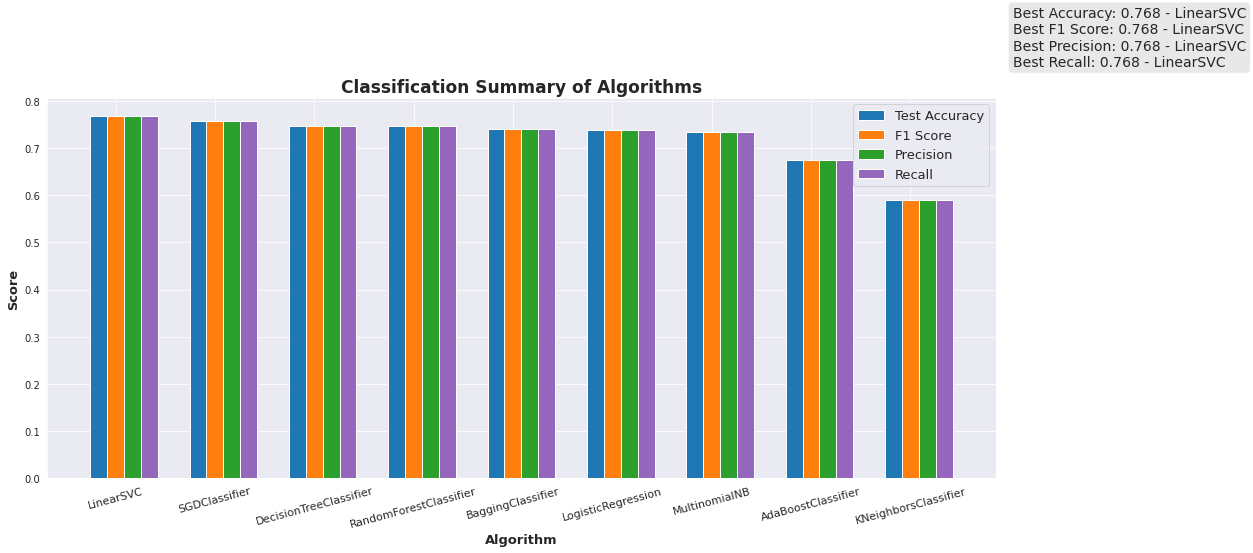

In [ ]:
sns.set_style('darkgrid')
plt.figure(figsize = (17, 7))

barWidth = 0.17

# set height of bar
bars1 = results['Accuracy: Test']
bars2 = results['F1 Score: Test']
bars3 = results['Precision: Test']
bars4 = results['Recall: Test']


# Set position of bar on X axis
r1 = np.arange(len(bars1))
r2 = [x + barWidth for x in r1]
r3 = [x + barWidth for x in r2]
r4 = [x + barWidth for x in r3]


# Make the plot
pal = sns.color_palette()
plt.bar(r1, bars1, color= pal[0], width=barWidth, edgecolor='white', label='Test Accuracy')
plt.bar(r2, bars2, color= pal[1], width=barWidth, edgecolor='white', label='F1 Score')
plt.bar(r3, bars3, color= pal[2], width=barWidth, edgecolor='white', label='Precision')
plt.bar(r4, bars4, color= pal[4], width=barWidth, edgecolor='white', label='Recall')


# Add xticks on the middle of the group bars
plt.xlabel('Algorithm', fontweight='bold', fontsize = 13)
plt.ylabel('Score', fontweight = 'bold', fontsize = 13)
plt.xticks([r + barWidth for r in range(len(bars1))], results['Algorithm'], rotation = 15, fontsize = 11)

# Create legend & Show graphic
plt.legend(fontsize = 13)

textstr = '\n'.join(['Best Accuracy: {:.3f} - {}'.format(best_acc['Accuracy: Test'].values[0], best_acc['Algorithm'].values[0]),
                     'Best F1 Score: {:.3f} - {}'.format(best_f1['F1 Score: Test'].values[0], best_f1['Algorithm'].values[0]),
                   'Best Precision: {:.3f} - {}'.format(best_precision['Precision: Test'].values[0], best_precision['Algorithm'].values[0]),
                    'Best Recall: {:.3f} - {}'.format(best_recall['Recall: Test'].values[0], best_recall['Algorithm'].values[0])])
props = dict(boxstyle='round', facecolor='lightgrey', alpha=0.5)

#place a text box
plt.text(9.2, 1, textstr, fontsize=14,
        verticalalignment='top', bbox=props)

plt.title('Classification Summary of Algorithms', fontweight = 'bold', fontsize = 17);

In [ ]:
# store the best/worst performance time
best_train_time = results[results['Training Time'] == results['Training Time'].min()]
worst_train_time = results[results['Training Time'] == results['Training Time'].max()]
best_prediction_time = results[results['Prediction Time'] == results['Prediction Time'].min()]
worst_prediction_time = results[results['Prediction Time'] == results['Prediction Time'].max()]

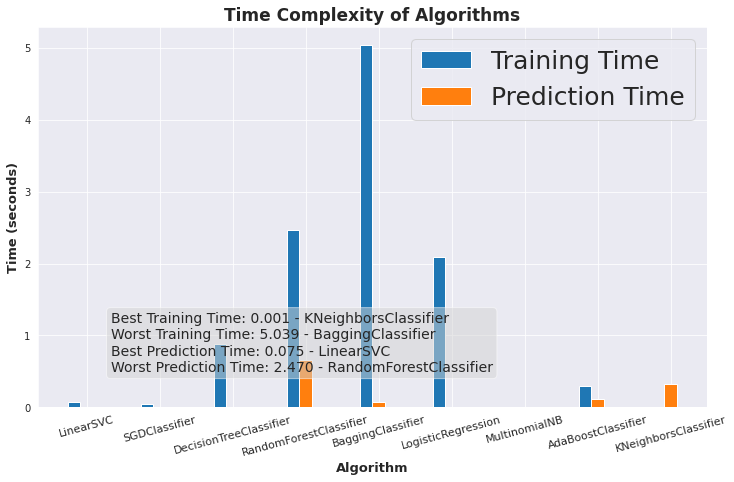

In [ ]:
plt.figure(figsize = (12, 7))

barWidth = 0.17

# set height of bar
bars1 = results['Training Time']
bars2 = results['Prediction Time']

# Set position of bar on X axis
r1 = np.arange(len(bars1))
r2 = [x + barWidth for x in r1]

# Make the plot
plt.bar(r1, bars1, color= pal[0], width=barWidth, edgecolor='white', label='Training Time')
plt.bar(r2, bars2, color= pal[1], width=barWidth, edgecolor='white', label='Prediction Time')

# Add xticks on the middle of the group bars
plt.xlabel('Algorithm', fontweight='bold', fontsize = 13)
plt.ylabel('Time (seconds)', fontweight = 'bold', fontsize = 13)
plt.xticks([r + barWidth for r in range(len(bars1))], results['Algorithm'], rotation = 15, fontsize = 11)

# Create legend & Show graphic
plt.legend(fontsize = 25)

textstr = '\n'.join(('Best Training Time: {:.3f} - {}'.format(best_train_time['Training Time'].values[0], best_train_time['Algorithm'].values[0]),
                     'Worst Training Time: {:.3f} - {}'.format(worst_train_time['Training Time'].values[0], worst_train_time['Algorithm'].values[0]),
                   'Best Prediction Time: {:.3f} - {}'.format(best_prediction_time['Training Time'].values[0], best_prediction_time['Algorithm'].values[0]),
                    'Worst Prediction Time: {:.3f} - {}'.format(worst_prediction_time['Training Time'].values[0], worst_prediction_time['Algorithm'].values[0])))

props = dict(boxstyle='round', facecolor='lightgrey', alpha=0.5)

#place a text box
plt.text(0.5, 0.5, textstr, fontsize=14,  bbox=props)

plt.title('Time Complexity of Algorithms', fontweight = 'bold', fontsize = 17);

### Tuning Hyperparameters
***

In [ ]:
def param_tuning(clf, param_dict, X_train, y_train, X_test, y_test):

    # make scorer object
    scorer = make_scorer(f1_score)

    # perform Grid Search for Parameters
    grid_obj = GridSearchCV(estimator = clf,
                           param_grid = param_dict,
                           scoring = scorer,
                           cv = 5)

    grid_fit = grid_obj.fit(X_train, y_train)

    # Get the estimator
    best_clf = grid_fit.best_estimator_

    # Make predictions using the unoptimized and model
    predictions = (clf.fit(X_train, y_train)).predict(X_test)
    best_predictions = best_clf.predict(X_test)

    # Report the before-and-afterscores
    print(clf.__class__.__name__)
    print("\nOptimized Model\n------")
    print("Best Parameters: {}".format(grid_fit.best_params_))
    print("Accuracy: {:.4f}".format(accuracy_score(y_test, best_predictions)))
    print("F1-score: {:.4f}".format(f1_score(y_test, best_predictions)))
    print("Precision: {:.4f}".format(precision_score(y_test, best_predictions)))
    print("Recall: {:.4f}".format(recall_score(y_test, best_predictions)))

Stochastic Gradient Classifier:

In [ ]:
# Dict for parameters
param_grid = {
    'alpha' : [0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.095, 0.0002, 0.0003],
    'max_iter' : [1000,2500, 3000, 4000,5000]
}

clf_sgd = SGDClassifier()

param_tuning(clf_sgd, param_grid, training_data, y_train, testing_data, y_test)

SGDClassifier

Optimized Model
------
Best Parameters: {'alpha': 0.08, 'max_iter': 2500}
Accuracy: 0.4967
F1-score: 0.6391
Precision: 0.4718
Recall: 0.9901


Logistic Regression Classifier:

In [ ]:
# Dict for parameters
param_grid = {
    'C': [1, 1.2, 1.3, 1.4,1.5,1.6,1.7,1.8,1.9,2.0,2.1,2.2]
}

clf_lr = LogisticRegression()

param_tuning(clf_lr, param_grid, training_data, y_train, testing_data, y_test)

LogisticRegression

Optimized Model
------
Best Parameters: {'C': 1.3}
Accuracy: 0.7672
F1-score: 0.7075
Precision: 0.8141
Recall: 0.6256


Decision Tree Classifier:

In [ ]:
param_grid = {
    'min_samples_split': [2,3,4,5,6,7,8],
    'min_samples_leaf': [1,2,3,4,5,6,7,8]
}

clf_dt = DecisionTreeClassifier()

param_tuning(clf_dt, param_grid, training_data, y_train, testing_data, y_test)

DecisionTreeClassifier

Optimized Model
------
Best Parameters: {'min_samples_leaf': 1, 'min_samples_split': 2}
Accuracy: 0.7428
F1-score: 0.6329
Precision: 0.8850
Recall: 0.4926


Random Forest Classifier:

In [ ]:
param_grid = {
    'n_estimators': [25,50,75,100,125,150],
    'min_samples_leaf': [1,2,3,4,5],
    'min_samples_split': [2,3,4,5]
}

clf_rf = RandomForestClassifier()

param_tuning(clf_rf, param_grid, training_data, y_train, testing_data, y_test)

RandomForestClassifier

Optimized Model
------
Best Parameters: {'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 50}
Accuracy: 0.7267
F1-score: 0.6455
Precision: 0.8175
Recall: 0.5333


Linear SVC:

In [ ]:
param_grid = {
    'C': [0.05,0.1,0.2,0.3,0.4,0.5, 0.75, 1, 1.2]
}

clf_linsvc = LinearSVC()

param_tuning(clf_linsvc, param_grid, training_data, y_train, testing_data, y_test)

LinearSVC

Optimized Model
------
Best Parameters: {'C': 0.1}
Accuracy: 0.7672
F1-score: 0.7075
Precision: 0.8141
Recall: 0.6256


In [ ]:
from google.colab import files
uploaded=files.upload()

Saving score.xlsx to score.xlsx


In [ ]:
import io
dfintensity=pd.read_excel(io.BytesIO(uploaded['score.xlsx']))
dfintensity.head(30)

,word,score
0,عاهره,0.5
1,شرموطه,0.5
2,كلب,0.4
3,تافه,0.4
4,سخيف,0.4
5,حيوان,0.4
6,خنزير,0.4
7,كتير,0.1
8,جدا,0.1
9,كثير,0.1


calcukate the intensity of cyberbullying

In [ ]:
text='أنتي وحدة هبلة و شرموطة'
#word=' كتير عاهره']
import re
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize
def intensityofcyberbullying(text):
  text = re.sub("[إأآا]", "ا", text)
  text = re.sub("ى", "ي", text)
  text = re.sub("ؤ", "ء", text)
  text = re.sub("ئ", "ء", text)
  text = re.sub("ة", "ه", text)
  text = re.sub("گ", "ك", text)
  list =word_tokenize(text)
  dfintensity['new'] =dfintensity.word.isin(list)
  dfintensity['new'].replace({False: 0, True: 1}, inplace=True)
  if  (dfintensity['new'] == 0).all():
    return ('0.0')
  else:
    intensity=dfintensity.groupby('new')['score'].sum()[1]
    if intensity>1:
      return (str(1.0))
    else:
           return (intensity)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
print(intensityofcyberbullying(text))

0.5


web app

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving templates.zip to templates.zip


In [ ]:
from zipfile import ZipFile
file_name = "/content/templates.zip"
with ZipFile(file_name, 'r') as zip:
  zip.extractall()
  print('Done')

Done


In [ ]:
!pip install flask_ngrok

In [ ]:
!pip install flask

In [ ]:
import flask
from flask import Flask, render_template, request
import pickle
import numpy as np
from flask_ngrok import run_with_ngrok
import warnings
warnings.filterwarnings('ignore')
import re
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize

app = Flask(__name__)
run_with_ngrok(app)

model = pickle.load(open('model.pkl', 'rb'))
@app.route('/', methods=['GET'])
def home():
  return render_template('index.html')

@app.route('/predict', methods=['GET', "POST"])
def predict():
  #selectValue = request.form.get('select1')
  #algorithm= str(selectValue)
  #if "predict" in request.form:
   text_values=request.form['text']
   input_values=request.form['text']
   algo = request.form.get("algo")
  #input_values = request.args.get('text')
   test_phrase = [input_values]
   test_phrase_counts = count_vector.transform(test_phrase)
  #if algorithm=="Support Vector Machine":
   if algo=="SVM":
    test_phrase_preds = model.predict(test_phrase_counts)
   elif algo=="MultinomialNB":
      test_phrase_preds = modelMultinomialNB.predict(test_phrase_counts)
   elif algo=="DecisionTree":
      test_phrase_preds = modelDecisionTree.predict(test_phrase_counts)
   elif algo=="KNeighbors":
      test_phrase_preds = modelKNeighbors.predict(test_phrase_counts)
   elif algo=="Logistic":
      test_phrase_preds = modelRegression.predict(test_phrase_counts)
  #elif algorithm=="MultinomialNB":
   #test_phrase_preds = modelMultinomialNB.predict(test_phrase_counts)
  #elif algorithm =="Decision Tree":
   #test_phrase_preds = modelDecisionTree.predict(test_phrase_counts)
   if test_phrase_preds == 0:
        return render_template('index.html', prediction_text= str(intensityofcyberbullying(text_values))+' =ليس تنمر، شدة التنمر')
   elif test_phrase_preds == 1:
         return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' =تنمر عام، شدة التنمر')
   elif test_phrase_preds == 2:
         return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' =تنمر بدعاء على الشخص، شدة التنمر ')
   elif test_phrase_preds == 3:
         return render_template('index.html', prediction_text= str(intensityofcyberbullying(text_values))+' =تنمر تشبيه الأنسان بحيوان أو صفة سيئة أو شيء معين، شدة التنمر ')
   elif test_phrase_preds == 4:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' =تنمر حضاري، شدة التنمر ')
   elif test_phrase_preds == 5:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' =تنمر جنسي، شدة التنمر ')
   elif test_phrase_preds == 6:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' =تنمر جنسي فيزيائي، شدة التنمر ')
   elif test_phrase_preds == 7:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values)) +' =تنمر ديني، شدة التنمر ')
   elif test_phrase_preds == 8:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values))+' = تنمر طائفي، شدة التنمر ')
   elif test_phrase_preds == 9:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values)) +' =تنمر عرقي، شدة التنمر ')
   elif test_phrase_preds == 10:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values)) +' =تنمر عنصري، شدة التنمر ')
   elif test_phrase_preds == 11:
          return render_template('index.html', prediction_text=str(intensityofcyberbullying(text_values)) +' =تنمر ساسي، شدة التنمر ')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
app.run()

 * Serving Flask app "__main__" (lazy loading)
 * Environment: production
   Use a production WSGI server instead.
 * Debug mode: off


 * Running on http://127.0.0.1:5000/ (Press CTRL+C to quit)


 * Running on http://5fe7-34-73-220-85.ngrok.io
 * Traffic stats available on http://127.0.0.1:4040


127.0.0.1 - - [02/Sep/2021 10:54:07] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:54:16] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [02/Sep/2021 10:54:51] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:55:17] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:56:27] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:56:41] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:57:28] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:57:48] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:58:30] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:59:29] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:59:38] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:59:47] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 10:59:55] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [02/Sep/2021 11:00:07] "POST /predict HTTP/1.1" 200 -
